# Employee Data Analysis – Visualisation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
sns.set_theme(style="whitegrid")

colors = ["#4472C4", "#ED7D31", "#70AD47",
          "#A5A5A5", "#FFC000"]

In [3]:
os.makedirs("../reports/figures", exist_ok=True)

In [4]:
df = pd.read_csv("../data/employees.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/employees.csv'

In [5]:
../data/employees.csv

SyntaxError: invalid syntax (976165825.py, line 1)

In [6]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current directory:
C:\Users\hp\Desktop\python\18 11 26\task2\ai-training-week1\employee-data-analysis

Files and folders:
['.gitignore', '.ipynb_checkpoints', 'data', 'exploratory_analysis.ipynb', 'notebooks', 'README.md', 'Untitled.ipynb', 'untitled.py']


In [7]:
for root, dirs, files in os.walk(".."):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

..\employee-data-analysis\data\before_after_summary.csv
..\employee-data-analysis\data\clean_data.csv
..\employee-data-analysis\data\employees.csv
..\employee-data-analysis\data\ibm_hr.csv


In [8]:
df = pd.read_csv("data/employees.csv")

df.head()

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte

In [9]:
df = pd.read_csv("data/employees.csv", encoding="utf-16")

df.head()

,1,Arun,Chennai
0,2,Priya,Mumbai
1,3,Rahul,Bangalore
2,4,Divya,Chennai


In [10]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (3, 3)

Columns:
['1', 'Arun', 'Chennai']


In [11]:
df = pd.read_csv("data/ibm_hr.csv", encoding="utf-16")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

UnicodeDecodeError: 'utf-16' codec can't decode bytes in position 0-1: Stream does not start with BOM

In [12]:
with open("data/ibm_hr.csv", "rb") as file:
    raw_data = file.read(100)

print(raw_data)

b'\xef\xbb\xbfAge,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,Emplo'


In [13]:
import chardet

with open("data/ibm_hr.csv", "rb") as file:
    result = chardet.detect(file.read())

print(result)

ModuleNotFoundError: No module named 'chardet'

In [14]:
%pip install chardet

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   -------- ------------------------------- 0.3/1.3 MB ? eta -:--:--
   ------------------------ --------------- 0.8/1.3 MB 2.8 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 2.6 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [15]:
import chardet

with open("data/ibm_hr.csv", "rb") as file:
    result = chardet.detect(file.read())

print(result)

{'encoding': 'UTF-8-SIG', 'confidence': 1.0, 'language': 'en', 'mime_type': 'text/plain'}


In [16]:
df = pd.read_csv("data/ibm_hr.csv", encoding="utf-8-sig")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [17]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

Shape: (1470, 35)

Columns:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Missing values:
0


## 1. Department-wise Employee Count

This bar chart shows the number of employees in each department.

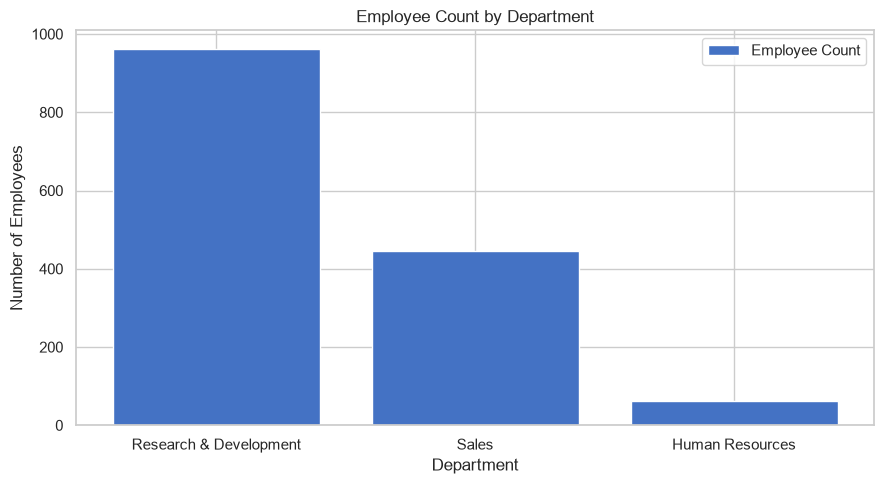

In [18]:
plt.figure(figsize=(9, 5))

department_count = df["Department"].value_counts()

plt.bar(
    department_count.index,
    department_count.values,
    color=colors[0],
    label="Employee Count"
)

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/01_department_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Insight:** The Research & Development department has the highest number of employees, followed by Sales and Human Resources.

In [ ]:
print(os.listdir("reports/figures/"))

['01_department_bar.png']


## 2. Employee Age Distribution

This histogram shows the distribution of employee ages.

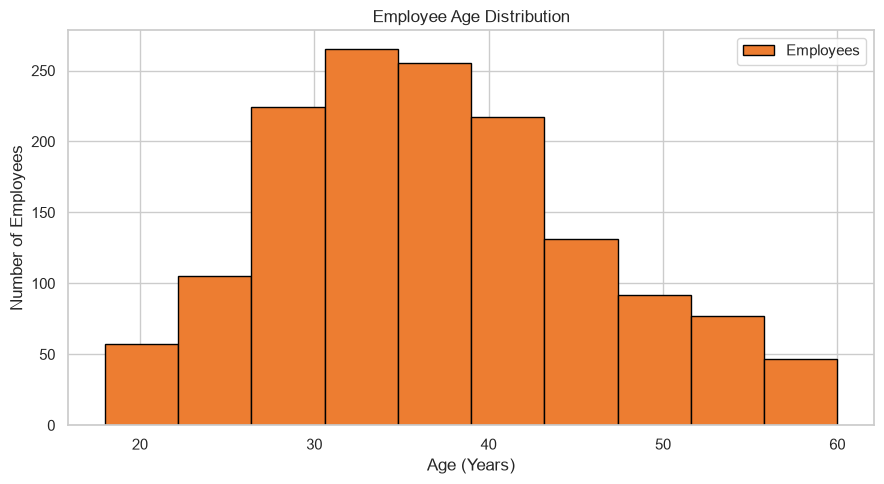

In [20]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Age"],
    bins=10,
    color=colors[1],
    edgecolor="black",
    label="Employees"
)

plt.title("Employee Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Employees")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/02_age_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Insight:** The histogram shows that most employees are concentrated in the younger and middle-age groups, with fewer employees in the older age groups.

In [ ]:
print(os.listdir("reports/figures/"))

['01_department_bar.png', '02_age_histogram.png']


## 3. Monthly Income vs Years at Company

This scatter plot examines the relationship between employee tenure and monthly income.

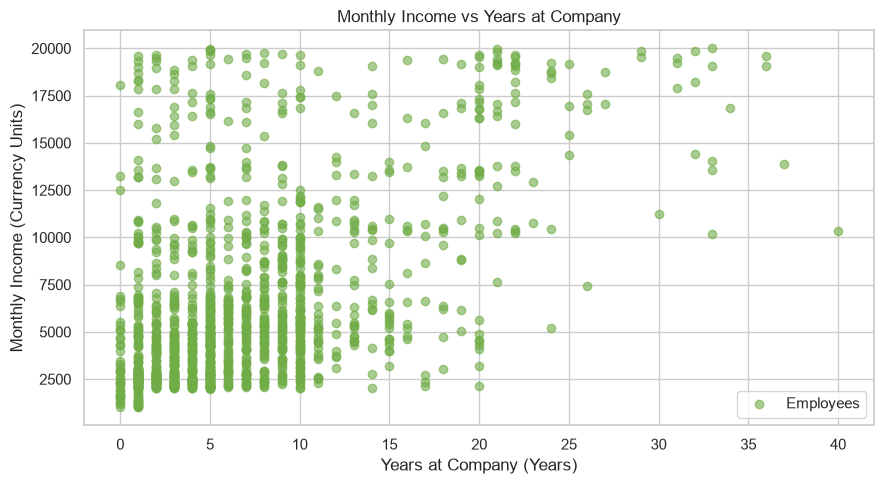

In [22]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["YearsAtCompany"],
    df["MonthlyIncome"],
    color=colors[2],
    alpha=0.6,
    label="Employees"
)

plt.title("Monthly Income vs Years at Company")
plt.xlabel("Years at Company (Years)")
plt.ylabel("Monthly Income (Currency Units)")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/03_income_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Insight:** Monthly income varies across employees with different years of service, indicating that company tenure alone does not determine employee income.

In [ ]:
print(os.listdir("reports/figures/"))

['01_department_bar.png', '02_age_histogram.png', '03_income_scatter.png']


## 4. Sorted Employee Monthly Income

This line chart displays employee monthly income in ascending order.

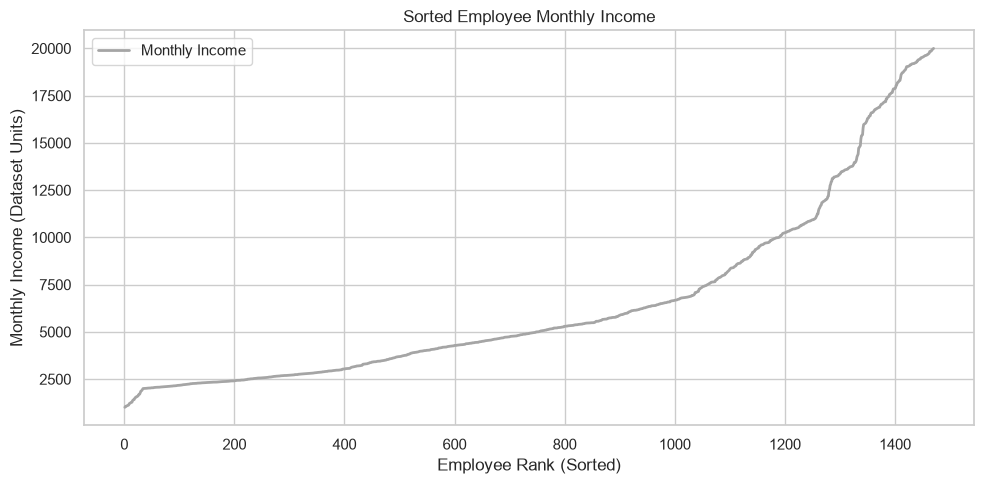

In [24]:
plt.figure(figsize=(10, 5))

sorted_income = df["MonthlyIncome"].sort_values().reset_index(drop=True)

plt.plot(
    sorted_income.index + 1,
    sorted_income,
    color=colors[3],
    linewidth=2,
    label="Monthly Income"
)

plt.title("Sorted Employee Monthly Income")
plt.xlabel("Employee Rank (Sorted)")
plt.ylabel("Monthly Income (Dataset Units)")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/04_income_line.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Insight:** Employee monthly income increases across the sorted ranking, showing a wide difference between the lowest-paid and highest-paid employees.

In [ ]:
print(os.listdir("reports/figures/"))

['01_department_bar.png', '02_age_histogram.png', '03_income_scatter.png', '04_income_line.png']


## 5. Employee Data Correlation Heatmap

This heatmap displays correlations between numerical employee attributes.

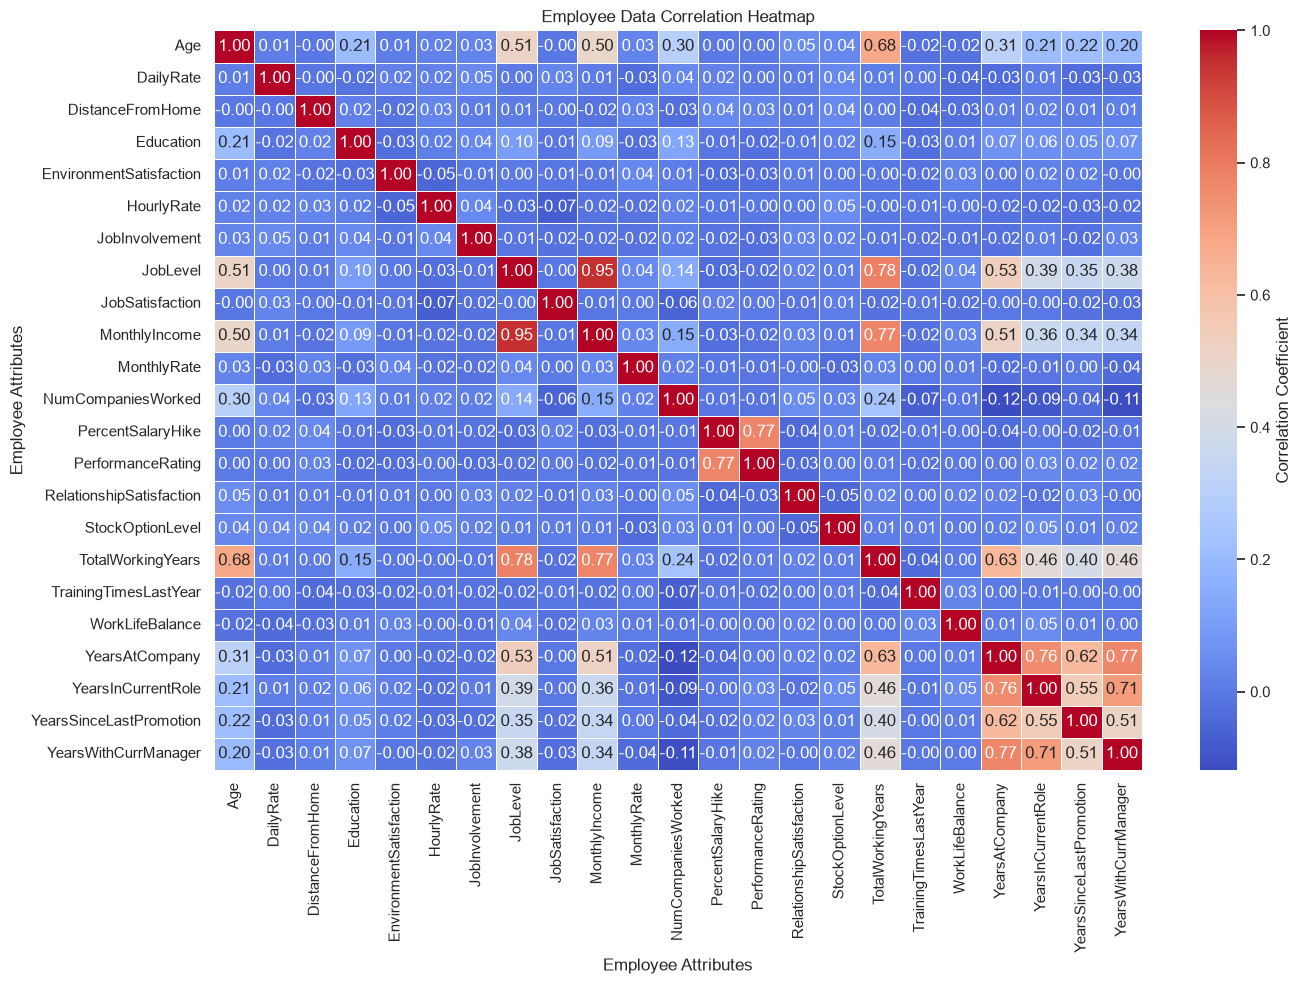

In [26]:
numeric_df = df.select_dtypes(include="number")

exclude_columns = [
    "EmployeeNumber",
    "EmployeeCount",
    "StandardHours"
]

numeric_df = numeric_df.drop(
    columns=exclude_columns,
    errors="ignore"
)

correlation = numeric_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title("Employee Data Correlation Heatmap")
plt.xlabel("Employee Attributes")
plt.ylabel("Employee Attributes")

plt.tight_layout()

plt.savefig(
    "../reports/figures/05_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Insight:** The heatmap highlights relationships between employee attributes, helping identify which numerical factors are positively or negatively associated.

In [ ]:
print(os.listdir("reports/figures/"))

['01_department_bar.png', '02_age_histogram.png', '03_income_scatter.png', '04_income_line.png', '05_correlation_heatmap.png']
